## Part 3: Combine SATCAT and TLE data
#### 1. Combine the content of the 'DS_decayedLEODebris.csv' and 'DS_SpaceTrack' based on the Norad ID

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', None)

# read data SATCAT data from csv
decayedLEODebris_df = pd.read_csv('../Data/DS_decayedLEODebris.csv')
decayedLEODebris_df

,INTLDES,NORAD_CAT_ID,OBJECT_TYPE,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,PERIOD,INCLINATION,APOGEE,PERIGEE,COMMENT,COMMENTCODE,RCSVALUE,RCS_SIZE,FILE,LAUNCH_YEAR,LAUNCH_NUM,LAUNCH_PIECE,CURRENT,OBJECT_NAME,OBJECT_ID,OBJECT_NUMBER
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,NaN,4.0,0,LARGE,1,1957,1,A,Y,SL-1 R/B,1957-001A,1
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN,NaN,0,NaN,1,1958,4,A,Y,SL-1 R/B,1958-004A,7
2,1960-003A,30,ROCKET BODY,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,88.38,51.25,194.0,194.0,NaN,NaN,0,NaN,1,1960,3,A,Y,THOR ABLESTAR R/B,1960-003A,30
3,1960-003C,33,DEBRIS,THOR ABLESTAR DEB,US,1960-04-13,AFETR,1960-07-17,93.59,51.29,615.0,285.0,NaN,NaN,0,NaN,1,1960,3,C,Y,THOR ABLESTAR DEB,1960-003C,33
4,1960-005B,35,ROCKET BODY,SL-3 R/B,CIS,1960-05-15,TTMTR,1960-07-17,88.48,64.89,199.0,199.0,NaN,NaN,0,NaN,1,1960,5,B,Y,SL-3 R/B,1960-005B,35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25688,1999-025TC,30147,DEBRIS,FENGYUN 1C DEB,PRC,1999-05-10,TSC,2025-01-29,92.21,99.00,409.0,357.0,NaN,NaN,0,SMALL,9025,1999,25,TC,Y,FENGYUN 1C DEB,1999-025TC,30147
25689,1997-051DS,34107,DEBRIS,IRIDIUM 33 DEB,US,1997-09-14,TTMTR,2025-01-29,88.69,86.36,222.0,197.0,NaN,NaN,0,SMALL,9025,1997,51,DS,Y,IRIDIUM 33 DEB,1997-051DS,34107
25690,2024-140FC,60777,DEBRIS,CZ-6A DEB,PRC,2024-08-06,TSC,2025-01-29,88.82,89.46,237.0,195.0,NaN,NaN,0,SMALL,9025,2024,140,FC,Y,CZ-6A DEB,2024-140FC,60777
25691,2024-140SW,61285,DEBRIS,CZ-6A DEB,PRC,2024-08-06,TSC,2025-01-29,88.90,89.25,238.0,202.0,NaN,NaN,0,SMALL,9025,2024,140,SW,Y,CZ-6A DEB,2024-140SW,61285


In [8]:
# read ELSET data from csv
TLEs_df = pd.read_csv('../Data/DS_TLEs.csv')
TLEs_df

,Unnamed: 0,ORDINAL,COMMENT,ORIGINATOR,NORAD_CAT_ID,OBJECT_NAME,OBJECT_TYPE,CLASSIFICATION_TYPE,INTLDES,EPOCH,EPOCH_MICROSECONDS,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,EPHEMERIS_TYPE,ELEMENT_SET_NO,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,FILE,TLE_LINE0,TLE_LINE1,TLE_LINE2,OBJECT_ID,OBJECT_NUMBER,SEMIMAJOR_AXIS,PERIOD,APOGEE,PERIGEE,DECAYED
0,0,1,GENERATED VIA SPACETRACK.ORG API,18 SPCS,30,THOR ABLESTAR R/B,ROCKET BODY,U,60003A,1961-08-16 14:24:53,774496,16.293583,0.000000,51.2500,356.4892,331.9473,28.0526,0,999,7590,0.000000,0.021256,0.000000,33907,0 THOR ABLESTAR R/B,1 00030U 60003 A 61228.60062239 .02125614 +0...,2 00030 051.2500 356.4892 0000000 331.9473 028...,1960-003A,30,6572.406,88.378,194.271,194.271,1
1,1,1,GENERATED VIA SPACETRACK.ORG API,18 SPCS,33,THOR ABLESTAR DEB,DEBRIS,U,60003C,1960-10-06 07:59:06,496512,15.383434,0.024276,51.2879,136.0668,196.7800,163.6100,0,999,2700,0.000000,0.000019,0.000000,33906,0 THOR ABLESTAR DEB,1 00033U 60003 C 60280.33271408 .00001932 +0...,2 00033 051.2879 136.0668 0242757 196.7800 163...,1960-003C,33,6829.149,93.607,616.797,285.232,1
2,2,1,GENERATED VIA SPACETRACK.ORG API,18 SPCS,35,SL-3 R/B,ROCKET BODY,U,60005B,1960-07-16 04:00:11,150208,16.275237,0.000000,64.8899,44.6976,36.3819,323.6180,0,999,990,0.000000,0.032711,0.000000,33906,0 SL-3 R/B,1 00035U 60005 B 60198.16679572 .03271057 +0...,2 00035 064.8899 044.6976 0000000 036.3819 323...,1960-005B,35,6577.344,88.478,199.209,199.209,1
3,3,1,GENERATED VIA SPACETRACK.ORG API,18 SPCS,37,SPUTNIK 4 DEB,DEBRIS,U,60005D,1961-03-15 15:48:42,802271,15.498003,0.019840,64.8899,343.2411,333.4201,27.0840,0,999,4690,0.000000,0.000390,0.000000,33907,0 SPUTNIK 4 DEB,1 00037U 60005 D 61074.65882873 .00039007 +0...,2 00037 064.8899 343.2411 0198403 333.4201 027...,1960-005D,37,6795.451,92.915,552.140,282.492,1
4,4,1,GENERATED VIA SPACETRACK.ORG API,18 SPCS,38,SPUTNIK 4 DEB,DEBRIS,U,60005E,1960-08-19 16:34:33,722976,15.889090,0.003421,64.8899,302.1218,49.4823,310.6691,0,999,1500,0.000000,0.006108,0.000000,33906,0 SPUTNIK 4 DEB,1 00038U 60005 E 60232.69066809 .00610805 +0...,2 00038 064.8899 302.1218 0034213 049.4823 310...,1960-005E,38,6683.482,90.628,328.213,282.481,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24592,24592,1,GENERATED VIA SPACETRACK.ORG API,18 SPCS,61985,CZ-7 DEB,DEBRIS,U,24211C,2024-11-17 02:56:46,596192,15.999710,0.013893,41.3258,230.1136,163.0962,197.4583,0,999,22,0.006299,0.110698,0.000007,4558807,0 CZ-7 DEB,1 61985U 24211C 24322.12276153 .11069787 6...,2 61985 41.3258 230.1136 0138930 163.0962 197...,2024-211C,61985,6652.636,90.002,366.926,182.076,1
24593,24593,1,GENERATED VIA SPACETRACK.ORG API,18 SPCS,61986,CZ-7 DEB,DEBRIS,U,24211D,2024-11-16 18:05:14,991936,15.806407,0.020526,41.6383,232.5019,189.0244,170.6889,0,999,16,0.005890,0.062043,0.000007,4558217,0 CZ-7 DEB,1 61986U 24211D 24321.75364574 .06204315 6...,2 61986 41.6383 232.5019 0205265 189.0244 170...,2024-211D,61986,6706.765,91.102,466.296,190.963,1
24594,24594,1,GENERATED VIA SPACETRACK.ORG API,18 SPCS,61987,CZ-7 DEB,DEBRIS,U,24211E,2024-11-16 02:52:39,26496,15.745004,0.022269,41.8022,236.3926,178.1516,182.0204,0,999,6,0.005594,0.047777,0.000007,4558807,0 CZ-7 DEB,1 61987U 24211E 24321.11989614 .04777669 6...,2 61987 41.8022 236.3926 0222688 178.1516 182...,2024-211E,61987,6724.190,91.458,495.795,196.316,1
24595,24595,1,GENERATED VIA SPACETRACK.ORG API,18 SPCS,62031,SL-4 R/B,ROCKET BODY,U,24215B,2024-11-23 05:51:19,890144,16.431831,0.001187,51.6438,246.9269,76.8603,51.8089,0,999,28,0.000403,0.110072,0.000013,4561069,0 SL-4 R/B,1 62031U 24215B 24328.24398021 .11007155 1...,2 62031 51.6438 246.9269 0011875 76.8603 51...,2024-215B,62031,6535.486,87.635,165.112,149.590,1


In [9]:
# merge the two dataframes with outer join
combined_df = pd.merge(decayedLEODebris_df, TLEs_df, on='NORAD_CAT_ID', how='outer')
combined_df

,INTLDES_x,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,PERIOD_x,INCLINATION_x,APOGEE_x,PERIGEE_x,COMMENT_x,COMMENTCODE,RCSVALUE,RCS_SIZE,FILE_x,LAUNCH_YEAR,LAUNCH_NUM,LAUNCH_PIECE,CURRENT,OBJECT_NAME_x,OBJECT_ID_x,OBJECT_NUMBER_x,Unnamed: 0,ORDINAL,COMMENT_y,ORIGINATOR,OBJECT_NAME_y,OBJECT_TYPE_y,CLASSIFICATION_TYPE,INTLDES_y,EPOCH,EPOCH_MICROSECONDS,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,EPHEMERIS_TYPE,ELEMENT_SET_NO,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,FILE_y,TLE_LINE0,TLE_LINE1,TLE_LINE2,OBJECT_ID_y,OBJECT_NUMBER_y,SEMIMAJOR_AXIS,PERIOD_y,APOGEE_y,PERIGEE_y,DECAYED
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,NaN,4.0,0,LARGE,1,1957,1,A,Y,SL-1 R/B,1957-001A,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN,NaN,0,NaN,1,1958,4,A,Y,SL-1 R/B,1958-004A,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1959-009B,23,ROCKET BODY,JUNO II R/B,US,1959-10-13,AFETR,1989-07-16,89.24,50.27,249.0,225.0,NaN,NaN,0,MEDIUM,5942,1959,9,B,Y,JUNO II R/B,1959-009B,23,7228.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,JUNO II R/B,ROCKET BODY,U,59009B,1989-07-14 18:51:46,968192.0,16.135613,0.001834,50.2674,226.9734,32.5712,327.5638,0.0,999.0,58050.0,0.003007,0.027318,0.019637,34586.0,0 JUNO II R/B,1 00023U 59009 B 89195.78596028 .02731772 +1...,2 00023 050.2674 226.9734 0018343 032.5712 327...,1959-009B,23.0,6615.233,89.244,249.232,224.964,1.0
3,1960-002A,28,ROCKET BODY,THOR ABLE R/B,US,1960-04-01,AFETR,1991-07-03,87.80,48.34,168.0,163.0,NaN,NaN,0,LARGE,5942,1960,2,A,Y,THOR ABLE R/B,1960-002A,28,7229.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,THOR ABLE R/B,ROCKET BODY,U,60002A,1991-07-02 11:34:12,753984.0,16.401144,0.000363,48.3426,203.3369,333.1829,26.9220,0.0,999.0,67681.0,0.001474,0.208109,0.000057,34749.0,0 THOR ABLE R/B,1 00028U 60002 A 91183.48209206 .20810904 +5...,2 00028 048.3426 203.3369 0003628 333.1829 026...,1960-002A,28.0,6543.639,87.799,167.878,163.130,1.0
4,1960-003A,30,ROCKET BODY,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,88.38,51.25,194.0,194.0,NaN,NaN,0,NaN,1,1960,3,A,Y,THOR ABLESTAR R/B,1960-003A,30,0.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,THOR ABLESTAR R/B,ROCKET BODY,U,60003A,1961-08-16 14:24:53,774496.0,16.293583,0.000000,51.2500,356.4892,331.9473,28.0526,0.0,999.0,7590.0,0.000000,0.021256,0.000000,33907.0,0 THOR ABLESTAR R/B,1 00030U 60003 A 61228.60062239 .02125614 +0...,2 00030 051.2500 356.4892 0000000 331.9473 028...,1960-003A,30.0,6572.406,88.378,194.271,194.271,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25688,2024-219G,62087,ROCKET BODY,ELECTRON R/B,US,2024-11-25,RLLC,2024-12-07,87.61,97.92,185.0,128.0,NaN,NaN,0,LARGE,8978,2024,219,G,Y,ELECTRON R/B,2024-219G,62087,24400.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,ELECTRON R/B,ROCKET BODY,U,24219G,2024-12-07 17:52:24,594240.0,16.436123,0.004376,97.9193,143.6896,196.3431,294.5419,0.0,999.0,198.0,0.000359,0.242074,0.000002,4574592.0,0 ELECTRON R/B,1 62087U 24219G 24342.74472910 .24207401 2...,2 62087 97.9193 143.6896 0043756 196.3431 294...,2024-219G,62087.0,6534.348,87.612,184.804,127.621,1.0
25689,2024-221C,62113,ROCKET BODY,ZQ-2E R/B,PRC,2024-11-27,JSC,2024-12-24,87.60,49.89,184.0,127.0,NaN,NaN,0,LARGE,8990,2024,221,C,Y,ZQ-2E R/B,2024-221C,62113,24401.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,ZQ-2E R/B,ROCKET BODY,U,24221C,2024-12-24 06:33:51,112800.0,16.438900,0.004298,49.8914,275.2215,178.2700,320.2910,0.0,999.0,429.0,0.000232,0.170634,0.000012,4590190.0,0 ZQ-2E R/B,1 

#### 2. Examine the objects without TLE data to see if they can be dropped unproblematically

In [10]:
# extract rows whithout TLE data
missing_TLEs_df = combined_df[combined_df['TLE_LINE1'].isnull()].copy()
missing_TLEs_df

,INTLDES_x,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,PERIOD_x,INCLINATION_x,APOGEE_x,PERIGEE_x,COMMENT_x,COMMENTCODE,RCSVALUE,RCS_SIZE,FILE_x,LAUNCH_YEAR,LAUNCH_NUM,LAUNCH_PIECE,CURRENT,OBJECT_NAME_x,OBJECT_ID_x,OBJECT_NUMBER_x,Unnamed: 0,ORDINAL,COMMENT_y,ORIGINATOR,OBJECT_NAME_y,OBJECT_TYPE_y,CLASSIFICATION_TYPE,INTLDES_y,EPOCH,EPOCH_MICROSECONDS,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,EPHEMERIS_TYPE,ELEMENT_SET_NO,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,FILE_y,TLE_LINE0,TLE_LINE1,TLE_LINE2,OBJECT_ID_y,OBJECT_NUMBER_y,SEMIMAJOR_AXIS,PERIOD_y,APOGEE_y,PERIGEE_y,DECAYED
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,96.19,65.10,938.0,214.0,NaN,4.0,0,LARGE,1,1957,1,A,Y,SL-1 R/B,1957-001A,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,102.74,65.14,1571.0,206.0,NaN,NaN,0,NaN,1,1958,4,A,Y,SL-1 R/B,1958-004A,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
103,1962-019B,296,ROCKET BODY,ATLAS D 7 R/B,US,1962-05-24,AFETR,1962-05-25,88.80,32.50,292.0,138.0,NaN,NaN,0,NaN,1,1962,19,B,Y,ATLAS D 7 R/B,1962-019B,296,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
280,1963-036E,666,DEBRIS,ATLAS AGENA D DEB,US,1963-09-06,AFWTR,1963-09-10,87.90,94.30,171.0,170.0,NaN,5.0,0,NaN,1,1963,36,E,Y,ATLAS AGENA D DEB,1963-036E,666,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
296,1963-050C,709,DEBRIS,SL-7 DEB,CIS,1963-12-13,KYMTR,1964-01-03,89.60,48.90,284.0,232.0,NaN,5.0,0,NaN,1,1963,50,C,Y,SL-7 DEB,1963-050C,709,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20899,2011-050D,37833,DEBRIS,H-2A DEB,JPN,2011-09-23,TNSTA,2012-11-01,89.92,97.65,279.0,262.0,NaN,NaN,0,SMALL,7541,2011,50,D,Y,H-2A DEB,2011-050D,37833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21299,2013-011B,39121,ROCKET BODY,ATLAS 5 CENTAUR R/B,US,2013-03-19,AFETR,2014-11-22,92.28,21.40,644.0,129.0,NaN,NaN,0,LARGE,7337,2013,11,B,Y,ATLAS 5 CENTAUR R/B,2013-011B,39121,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21327,2013-050B,39257,ROCKET BODY,ATLAS 5 CENTAUR R/B,US,2013-09-18,AFETR,2015-02-08,93.14,19.23,753.0,103.0,NaN,NaN,0,LARGE,7337,2013,50,B,Y,ATLAS 5 CENTAUR R/B,2013-050B,39257,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21344,2013-055X,39289,DEBRIS,FALCON 9 DEB,US,2013-09-29,AFWTR,2013-10-13,92.94,80.99,534.0,302.0,NaN,NaN,0,SMALL,7337,2013,55,X,Y,FALCON 9 DEB,2013-055X,39289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# check how often which object type occurs in the missing TLE data and overall data
combined_type_counts = combined_df['OBJECT_TYPE_x'].value_counts(normalize=True) * 100
missing_type_counts = missing_TLEs_df['OBJECT_TYPE_x'].value_counts(normalize=True) * 100
print("Combined type counts: ", combined_type_counts, "\n")
print("Missing type counts: ", missing_type_counts)

# Plot the distribution as a pie chart
# combined_type_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['skyblue', 'lightgreen', 'lightcoral'])
# plt.title('Distribution of all Object Types')
# plt.ylabel('')  # Hide the y-label for the pie chart
# plt.show()
# missing_type_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['skyblue', 'lightgreen', 'lightcoral'])
# plt.title('Distribution of Object Types for objects without TLE data')
# plt.ylabel('')  # Hide the y-label for the pie chart
# plt.show()

Combined type counts:  OBJECT_TYPE_x
DEBRIS         84.470478
ROCKET BODY    15.529522
Name: proportion, dtype: float64 

Missing type counts:  OBJECT_TYPE_x
DEBRIS         90.328467
ROCKET BODY     9.671533
Name: proportion, dtype: float64


In [12]:
# check size of objects
combined_size_counts = (combined_df['RCS_SIZE'].value_counts(normalize=True) * 100).reindex(['SMALL', 'MEDIUM', 'LARGE'])
missing_size_counts = (missing_TLEs_df['RCS_SIZE'].value_counts(normalize=True) * 100).reindex(['SMALL', 'MEDIUM', 'LARGE'])
print("Combined size counts: ", combined_size_counts, "\n")
print("Missing size counts: ", missing_size_counts) 

Combined size counts:  RCS_SIZE
SMALL     64.075966
MEDIUM    19.709544
LARGE     16.214491
Name: proportion, dtype: float64 

Missing size counts:  RCS_SIZE
SMALL     54.166667
MEDIUM    19.166667
LARGE     26.666667
Name: proportion, dtype: float64


Missing_TLEs_df 'LAUNCH' column datatype:  datetime64[ns]
combined_df 'LAUNCH' column datatype:  datetime64[ns]


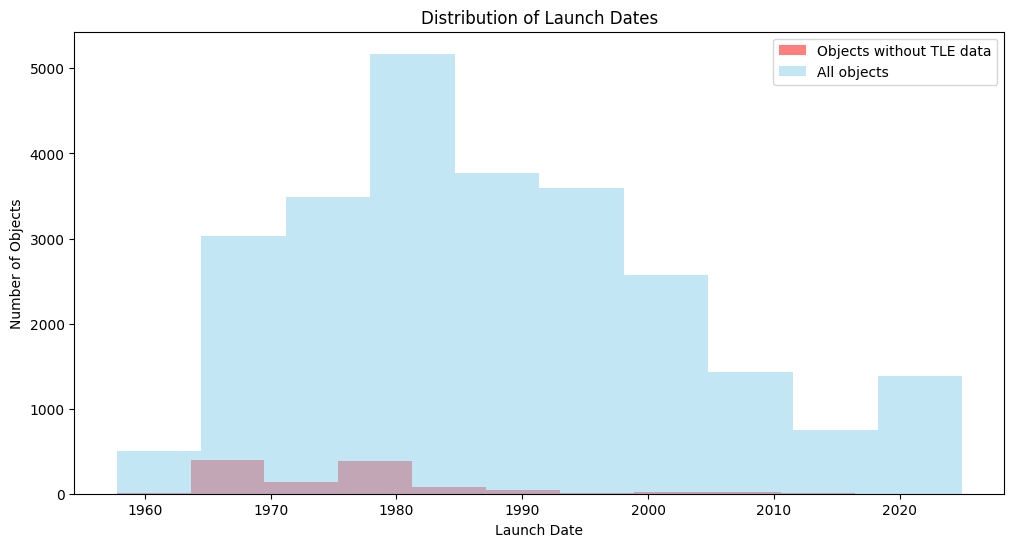

In [13]:
# display launch dates on a timeline
# convert the launch date to a datetime object
missing_TLEs_df['LAUNCH'] = pd.to_datetime(missing_TLEs_df['LAUNCH'])
combined_df['LAUNCH'] = pd.to_datetime(combined_df['LAUNCH'])

# show types of launch and decay date columns
print("Missing_TLEs_df 'LAUNCH' column datatype: ", missing_TLEs_df['LAUNCH'].dtype)
print("combined_df 'LAUNCH' column datatype: ", combined_df['LAUNCH'].dtype)

# plot the launch dates
plt.figure(figsize=(12, 6))
plt.hist(missing_TLEs_df['LAUNCH'], bins=10, color='red', alpha=0.5, label='Objects without TLE data')
plt.hist(combined_df['LAUNCH'], bins=10, color='skyblue', alpha=0.5, label='All objects')
plt.xlabel('Launch Date')
plt.ylabel('Number of Objects')
plt.title('Distribution of Launch Dates')
plt.legend()
plt.show()

Missing_TLEs_df 'DECAY' column datatype:  datetime64[ns]
combined_df 'DECAY' column datatype:  datetime64[ns]


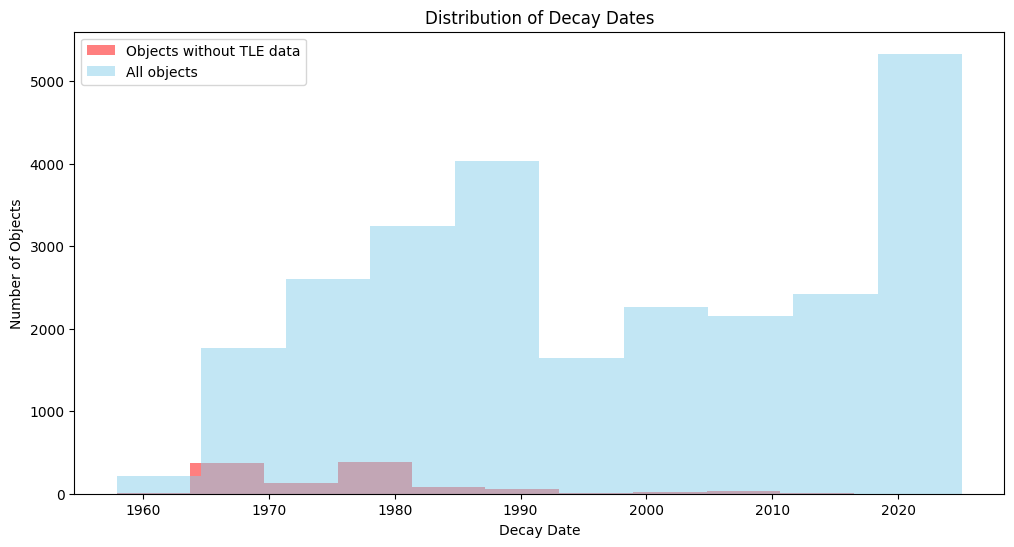

In [14]:
# display decay dates on a timeline
# convert the decay date to a datetime object
missing_TLEs_df['DECAY'] = pd.to_datetime(missing_TLEs_df['DECAY'])
combined_df['DECAY'] = pd.to_datetime(combined_df['DECAY'])

# check datatypes of decay date columns
print("Missing_TLEs_df 'DECAY' column datatype: ", missing_TLEs_df['DECAY'].dtype)
print("combined_df 'DECAY' column datatype: ", combined_df['DECAY'].dtype)

# plot the launch dates
plt.figure(figsize=(12, 6))
plt.hist(missing_TLEs_df['DECAY'], bins=10, color='red', alpha=0.5, label='Objects without TLE data')
plt.hist(combined_df['DECAY'], bins=10, color='skyblue', alpha=0.5, label='All objects')
plt.xlabel('Decay Date')
plt.ylabel('Number of Objects')
plt.title('Distribution of Decay Dates')
plt.legend()
plt.show()

In [15]:
# Calculate Lifetime of the Objects since the distribution of launch and decay dates is similar and suggests that maybe all objects had a too short lifetime to record TLEs
missing_TLEs_df.insert(8, 'LIFETIME', missing_TLEs_df['DECAY'] - missing_TLEs_df['LAUNCH'])
missing_TLEs_df

,INTLDES_x,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,LIFETIME,PERIOD_x,INCLINATION_x,APOGEE_x,PERIGEE_x,COMMENT_x,COMMENTCODE,RCSVALUE,RCS_SIZE,FILE_x,LAUNCH_YEAR,LAUNCH_NUM,LAUNCH_PIECE,CURRENT,OBJECT_NAME_x,OBJECT_ID_x,OBJECT_NUMBER_x,Unnamed: 0,ORDINAL,COMMENT_y,ORIGINATOR,OBJECT_NAME_y,OBJECT_TYPE_y,CLASSIFICATION_TYPE,INTLDES_y,EPOCH,EPOCH_MICROSECONDS,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,EPHEMERIS_TYPE,ELEMENT_SET_NO,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,FILE_y,TLE_LINE0,TLE_LINE1,TLE_LINE2,OBJECT_ID_y,OBJECT_NUMBER_y,SEMIMAJOR_AXIS,PERIOD_y,APOGEE_y,PERIGEE_y,DECAYED
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,58 days,96.19,65.10,938.0,214.0,NaN,4.0,0,LARGE,1,1957,1,A,Y,SL-1 R/B,1957-001A,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,202 days,102.74,65.14,1571.0,206.0,NaN,NaN,0,NaN,1,1958,4,A,Y,SL-1 R/B,1958-004A,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
103,1962-019B,296,ROCKET BODY,ATLAS D 7 R/B,US,1962-05-24,AFETR,1962-05-25,1 days,88.80,32.50,292.0,138.0,NaN,NaN,0,NaN,1,1962,19,B,Y,ATLAS D 7 R/B,1962-019B,296,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
280,1963-036E,666,DEBRIS,ATLAS AGENA D DEB,US,1963-09-06,AFWTR,1963-09-10,4 days,87.90,94.30,171.0,170.0,NaN,5.0,0,NaN,1,1963,36,E,Y,ATLAS AGENA D DEB,1963-036E,666,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
296,1963-050C,709,DEBRIS,SL-7 DEB,CIS,1963-12-13,KYMTR,1964-01-03,21 days,89.60,48.90,284.0,232.0,NaN,5.0,0,NaN,1,1963,50,C,Y,SL-7 DEB,1963-050C,709,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20899,2011-050D,37833,DEBRIS,H-2A DEB,JPN,2011-09-23,TNSTA,2012-11-01,405 days,89.92,97.65,279.0,262.0,NaN,NaN,0,SMALL,7541,2011,50,D,Y,H-2A DEB,2011-050D,37833,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21299,2013-011B,39121,ROCKET BODY,ATLAS 5 CENTAUR R/B,US,2013-03-19,AFETR,2014-11-22,613 days,92.28,21.40,644.0,129.0,NaN,NaN,0,LARGE,7337,2013,11,B,Y,ATLAS 5 CENTAUR R/B,2013-011B,39121,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21327,2013-050B,39257,ROCKET BODY,ATLAS 5 CENTAUR R/B,US,2013-09-18,AFETR,2015-02-08,508 days,93.14,19.23,753.0,103.0,NaN,NaN,0,LARGE,7337,2013,50,B,Y,ATLAS 5 CENTAUR R/B,2013-050B,39257,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
21344,2013-055X,39289,DEBRIS,FALCON 9 DEB,US,2013-09-29,AFWTR,2013-10-13,14 days,92.94,80.99,534.0,302.0,NaN,NaN,0,SMALL,7337,2013,55,X,Y,FALCON 9 DEB,2013-055X,39289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
# Calculate Lifetime of all objects
combined_df.insert(8, 'LIFETIME', combined_df['DECAY'] - combined_df['LAUNCH'])
combined_df

,INTLDES_x,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,LIFETIME,PERIOD_x,INCLINATION_x,APOGEE_x,PERIGEE_x,COMMENT_x,COMMENTCODE,RCSVALUE,RCS_SIZE,FILE_x,LAUNCH_YEAR,LAUNCH_NUM,LAUNCH_PIECE,CURRENT,OBJECT_NAME_x,OBJECT_ID_x,OBJECT_NUMBER_x,Unnamed: 0,ORDINAL,COMMENT_y,ORIGINATOR,OBJECT_NAME_y,OBJECT_TYPE_y,CLASSIFICATION_TYPE,INTLDES_y,EPOCH,EPOCH_MICROSECONDS,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,EPHEMERIS_TYPE,ELEMENT_SET_NO,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,FILE_y,TLE_LINE0,TLE_LINE1,TLE_LINE2,OBJECT_ID_y,OBJECT_NUMBER_y,SEMIMAJOR_AXIS,PERIOD_y,APOGEE_y,PERIGEE_y,DECAYED
0,1957-001A,1,ROCKET BODY,SL-1 R/B,CIS,1957-10-04,TTMTR,1957-12-01,58 days,96.19,65.10,938.0,214.0,NaN,4.0,0,LARGE,1,1957,1,A,Y,SL-1 R/B,1957-001A,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-004A,7,ROCKET BODY,SL-1 R/B,CIS,1958-05-15,TTMTR,1958-12-03,202 days,102.74,65.14,1571.0,206.0,NaN,NaN,0,NaN,1,1958,4,A,Y,SL-1 R/B,1958-004A,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1959-009B,23,ROCKET BODY,JUNO II R/B,US,1959-10-13,AFETR,1989-07-16,10869 days,89.24,50.27,249.0,225.0,NaN,NaN,0,MEDIUM,5942,1959,9,B,Y,JUNO II R/B,1959-009B,23,7228.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,JUNO II R/B,ROCKET BODY,U,59009B,1989-07-14 18:51:46,968192.0,16.135613,0.001834,50.2674,226.9734,32.5712,327.5638,0.0,999.0,58050.0,0.003007,0.027318,0.019637,34586.0,0 JUNO II R/B,1 00023U 59009 B 89195.78596028 .02731772 +1...,2 00023 050.2674 226.9734 0018343 032.5712 327...,1959-009B,23.0,6615.233,89.244,249.232,224.964,1.0
3,1960-002A,28,ROCKET BODY,THOR ABLE R/B,US,1960-04-01,AFETR,1991-07-03,11415 days,87.80,48.34,168.0,163.0,NaN,NaN,0,LARGE,5942,1960,2,A,Y,THOR ABLE R/B,1960-002A,28,7229.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,THOR ABLE R/B,ROCKET BODY,U,60002A,1991-07-02 11:34:12,753984.0,16.401144,0.000363,48.3426,203.3369,333.1829,26.9220,0.0,999.0,67681.0,0.001474,0.208109,0.000057,34749.0,0 THOR ABLE R/B,1 00028U 60002 A 91183.48209206 .20810904 +5...,2 00028 048.3426 203.3369 0003628 333.1829 026...,1960-002A,28.0,6543.639,87.799,167.878,163.130,1.0
4,1960-003A,30,ROCKET BODY,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,492 days,88.38,51.25,194.0,194.0,NaN,NaN,0,NaN,1,1960,3,A,Y,THOR ABLESTAR R/B,1960-003A,30,0.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,THOR ABLESTAR R/B,ROCKET BODY,U,60003A,1961-08-16 14:24:53,774496.0,16.293583,0.000000,51.2500,356.4892,331.9473,28.0526,0.0,999.0,7590.0,0.000000,0.021256,0.000000,33907.0,0 THOR ABLESTAR R/B,1 00030U 60003 A 61228.60062239 .02125614 +0...,2 00030 051.2500 356.4892 0000000 331.9473 028...,1960-003A,30.0,6572.406,88.378,194.271,194.271,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25688,2024-219G,62087,ROCKET BODY,ELECTRON R/B,US,2024-11-25,RLLC,2024-12-07,12 days,87.61,97.92,185.0,128.0,NaN,NaN,0,LARGE,8978,2024,219,G,Y,ELECTRON R/B,2024-219G,62087,24400.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,ELECTRON R/B,ROCKET BODY,U,24219G,2024-12-07 17:52:24,594240.0,16.436123,0.004376,97.9193,143.6896,196.3431,294.5419,0.0,999.0,198.0,0.000359,0.242074,0.000002,4574592.0,0 ELECTRON R/B,1 62087U 24219G 24342.74472910 .24207401 2...,2 62087 97.9193 143.6896 0043756 196.3431 294...,2024-219G,62087.0,6534.348,87.612,184.804,127.621,1.0
25689,2024-221C,62113,ROCKET BODY,ZQ-2E R/B,PRC,2024-11-27,JSC,2024-12-24,27 days,87.60,49.89,184.0,127.0,NaN,NaN,0,LARGE,8990,2024,221,C,Y,ZQ-2E R/B,2024-221C,62113,24401.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,ZQ-2E R/B,ROCKET BODY,U,24221C,2024-12-24 06:33:51,112800.0,16.438900,0.004298,49.8914,275.2215,178.2700

In [17]:
# review statistics of the lifetime columns
print("Lifetime statistics over all objects:")
print(combined_df['LIFETIME'].describe(), "\n")
print("Lifetime statistics over objects without TLE data:")
print(missing_TLEs_df['LIFETIME'].describe())

Lifetime statistics over all objects:
count                           25693
mean     3487 days 12:29:20.417234240
std      4749 days 16:41:01.798954304
min                   0 days 00:00:00
25%                  33 days 00:00:00
50%                 915 days 00:00:00
75%                5685 days 00:00:00
max               23115 days 00:00:00
Name: LIFETIME, dtype: object 

Lifetime statistics over objects without TLE data:
count                            1096
mean      443 days 22:07:00.437956208
std      1569 days 06:09:59.461599920
min                   0 days 00:00:00
25%                   5 days 00:00:00
50%                  14 days 00:00:00
75%                  22 days 00:00:00
max               12950 days 00:00:00
Name: LIFETIME, dtype: object


In [18]:
# drop objects without TLE data
combined_df.dropna(subset=['TLE_LINE1'], inplace=True)
combined_df

,INTLDES_x,NORAD_CAT_ID,OBJECT_TYPE_x,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,LIFETIME,PERIOD_x,INCLINATION_x,APOGEE_x,PERIGEE_x,COMMENT_x,COMMENTCODE,RCSVALUE,RCS_SIZE,FILE_x,LAUNCH_YEAR,LAUNCH_NUM,LAUNCH_PIECE,CURRENT,OBJECT_NAME_x,OBJECT_ID_x,OBJECT_NUMBER_x,Unnamed: 0,ORDINAL,COMMENT_y,ORIGINATOR,OBJECT_NAME_y,OBJECT_TYPE_y,CLASSIFICATION_TYPE,INTLDES_y,EPOCH,EPOCH_MICROSECONDS,MEAN_MOTION,ECCENTRICITY,INCLINATION_y,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,EPHEMERIS_TYPE,ELEMENT_SET_NO,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,FILE_y,TLE_LINE0,TLE_LINE1,TLE_LINE2,OBJECT_ID_y,OBJECT_NUMBER_y,SEMIMAJOR_AXIS,PERIOD_y,APOGEE_y,PERIGEE_y,DECAYED
2,1959-009B,23,ROCKET BODY,JUNO II R/B,US,1959-10-13,AFETR,1989-07-16,10869 days,89.24,50.27,249.0,225.0,NaN,NaN,0,MEDIUM,5942,1959,9,B,Y,JUNO II R/B,1959-009B,23,7228.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,JUNO II R/B,ROCKET BODY,U,59009B,1989-07-14 18:51:46,968192.0,16.135613,0.001834,50.2674,226.9734,32.5712,327.5638,0.0,999.0,58050.0,0.003007,0.027318,0.019637,34586.0,0 JUNO II R/B,1 00023U 59009 B 89195.78596028 .02731772 +1...,2 00023 050.2674 226.9734 0018343 032.5712 327...,1959-009B,23.0,6615.233,89.244,249.232,224.964,1.0
3,1960-002A,28,ROCKET BODY,THOR ABLE R/B,US,1960-04-01,AFETR,1991-07-03,11415 days,87.80,48.34,168.0,163.0,NaN,NaN,0,LARGE,5942,1960,2,A,Y,THOR ABLE R/B,1960-002A,28,7229.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,THOR ABLE R/B,ROCKET BODY,U,60002A,1991-07-02 11:34:12,753984.0,16.401144,0.000363,48.3426,203.3369,333.1829,26.9220,0.0,999.0,67681.0,0.001474,0.208109,0.000057,34749.0,0 THOR ABLE R/B,1 00028U 60002 A 91183.48209206 .20810904 +5...,2 00028 048.3426 203.3369 0003628 333.1829 026...,1960-002A,28.0,6543.639,87.799,167.878,163.130,1.0
4,1960-003A,30,ROCKET BODY,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,492 days,88.38,51.25,194.0,194.0,NaN,NaN,0,NaN,1,1960,3,A,Y,THOR ABLESTAR R/B,1960-003A,30,0.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,THOR ABLESTAR R/B,ROCKET BODY,U,60003A,1961-08-16 14:24:53,774496.0,16.293583,0.000000,51.2500,356.4892,331.9473,28.0526,0.0,999.0,7590.0,0.000000,0.021256,0.000000,33907.0,0 THOR ABLESTAR R/B,1 00030U 60003 A 61228.60062239 .02125614 +0...,2 00030 051.2500 356.4892 0000000 331.9473 028...,1960-003A,30.0,6572.406,88.378,194.271,194.271,1.0
5,1960-003C,33,DEBRIS,THOR ABLESTAR DEB,US,1960-04-13,AFETR,1960-07-17,95 days,93.59,51.29,615.0,285.0,NaN,NaN,0,NaN,1,1960,3,C,Y,THOR ABLESTAR DEB,1960-003C,33,1.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,THOR ABLESTAR DEB,DEBRIS,U,60003C,1960-10-06 07:59:06,496512.0,15.383434,0.024276,51.2879,136.0668,196.7800,163.6100,0.0,999.0,2700.0,0.000000,0.000019,0.000000,33906.0,0 THOR ABLESTAR DEB,1 00033U 60003 C 60280.33271408 .00001932 +0...,2 00033 051.2879 136.0668 0242757 196.7800 163...,1960-003C,33.0,6829.149,93.607,616.797,285.232,1.0
6,1960-005B,35,ROCKET BODY,SL-3 R/B,CIS,1960-05-15,TTMTR,1960-07-17,63 days,88.48,64.89,199.0,199.0,NaN,NaN,0,NaN,1,1960,5,B,Y,SL-3 R/B,1960-005B,35,2.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,SL-3 R/B,ROCKET BODY,U,60005B,1960-07-16 04:00:11,150208.0,16.275237,0.000000,64.8899,44.6976,36.3819,323.6180,0.0,999.0,990.0,0.000000,0.032711,0.000000,33906.0,0 SL-3 R/B,1 00035U 60005 B 60198.16679572 .03271057 +0...,2 00035 064.8899 044.6976 0000000 036.3819 323...,1960-005B,35.0,6577.344,88.478,199.209,199.209,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25688,2024-219G,62087,ROCKET BODY,ELECTRON R/B,US,2024-11-25,RLLC,2024-12-07,12 days,87.61,97.92,185.0,128.0,NaN,NaN,0,LARGE,8978,2024,219,G,Y,ELECTRON R/B,2024-219G,62087,24400.0,1.0,GENERATED VIA SPACETRACK.ORG API,18 SPCS,ELECTRON R/B,ROCKET BODY,U,24219G,2024-12-07 17:52:24,594240.0,16.436123,0.004376,97.9193,143.6896,196.3431,294.5419,0.0,999.0,198.0,0.000359,0.242074,0

#### 3. Drop not needed columns: Check duplicate columns to see if they contain the same values.  If they do not, check why and which one makes more sense to drop. 


In [19]:
# compare columns with same content to check if they contain the same values
# List of column names to compare
columns_to_compare = [
    'INTLDES', 'OBJECT_TYPE', 'PERIOD', 'INCLINATION', 'APOGEE', 'PERIGEE',
    'COMMENT', 'FILE', 'OBJECT_NAME', 'OBJECT_ID', 'OBJECT_NUMBER'
]

# Initialize a dictionary to store the columns that are not equal
unequal_columns = {}

# Loop through the columns and check for inequality
for col in columns_to_compare:
    are_equal = combined_df[f'{col}_x'].equals(combined_df[f'{col}_y'])
    print(f"{col}: {are_equal}")
    if not are_equal:
        unequal_columns[f'{col}_x'] = combined_df[f'{col}_x']
        unequal_columns[f'{col}_y'] = combined_df[f'{col}_y']

# Create a DataFrame out of the unequal columns
unequal_df = pd.DataFrame(unequal_columns)

print("\nComparison of unequal columns side by side:")
unequal_df

INTLDES: False
OBJECT_TYPE: True
PERIOD: False
INCLINATION: False
APOGEE: False
PERIGEE: False
COMMENT: False
FILE: False
OBJECT_NAME: True
OBJECT_ID: False
OBJECT_NUMBER: False

Comparison of unequal columns side by side:


,INTLDES_x,INTLDES_y,PERIOD_x,PERIOD_y,INCLINATION_x,INCLINATION_y,APOGEE_x,APOGEE_y,PERIGEE_x,PERIGEE_y,COMMENT_x,COMMENT_y,FILE_x,FILE_y,OBJECT_ID_x,OBJECT_ID_y,OBJECT_NUMBER_x,OBJECT_NUMBER_y
2,1959-009B,59009B,89.24,89.244,50.27,50.2674,249.0,249.232,225.0,224.964,NaN,GENERATED VIA SPACETRACK.ORG API,5942,34586.0,1959-009B,1959-009B,23,23.0
3,1960-002A,60002A,87.80,87.799,48.34,48.3426,168.0,167.878,163.0,163.130,NaN,GENERATED VIA SPACETRACK.ORG API,5942,34749.0,1960-002A,1960-002A,28,28.0
4,1960-003A,60003A,88.38,88.378,51.25,51.2500,194.0,194.271,194.0,194.271,NaN,GENERATED VIA SPACETRACK.ORG API,1,33907.0,1960-003A,1960-003A,30,30.0
5,1960-003C,60003C,93.59,93.607,51.29,51.2879,615.0,616.797,285.0,285.232,NaN,GENERATED VIA SPACETRACK.ORG API,1,33906.0,1960-003C,1960-003C,33,33.0
6,1960-005B,60005B,88.48,88.478,64.89,64.8899,199.0,199.209,199.0,199.209,NaN,GENERATED VIA SPACETRACK.ORG API,1,33906.0,1960-005B,1960-005B,35,35.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25688,2024-219G,24219G,87.61,87.612,97.92,97.9193,185.0,184.804,128.0,127.621,NaN,GENERATED VIA SPACETRACK.ORG API,8978,4574592.0,2024-219G,2024-219G,62087,62087.0
25689,2024-221C,24221C,87.60,87.597,49.89,49.8914,184.0,183.558,127.0,127.396,NaN,GENERATED VIA SPACETRACK.ORG API,8990,4590190.0,2024-221C,2024-221C,62113,62113.0
25690,2024-228B,24228B,88.60,88.597,46.09,46.0912,294.0,293.973,116.0,116.233,NaN,GENERATED VIA SPACETRACK.ORG API,8970,4572513.0,2024-228B,2024-228B,62191,62191.0
25691,2024-248C,24248C,87.73,87.734,97.51,97.5072,196.0,196.397,128.0,128.191,NaN,GENERATED VIA SPACETRACK.ORG API,9000,4595397.0,2024-248C,2024-248C,62408,62408.0


In [ ]:
# check difference between object ids since they seem the same
# Compare the OBJECT_ID columns line by line
unequal_mask = combined_df['OBJECT_ID_x'] != combined_df['OBJECT_ID_y']

# Filter the DataFrame to get the rows where the values are not the same
unequal_rows = combined_df[unequal_mask]

# Select only the OBJECT_ID columns 
unequal_object_ids = unequal_rows[['OBJECT_ID_x', 'OBJECT_ID_y']]

# display all rows with unequal object ids
pd.set_option('display.max_rows', None)
print(unequal_object_ids)

In [16]:
# the differences seem to come from the fact that ELSET data (-_y) gets updated more frequently and reflects fragmentations and reassignments 
# the SATCAT data (-_x) retains historical launch assignments 
# since OBJECT_ID and INTLDES represent the same information it makes most sense to use OBJECT_ID_y out of the four since it is the more actual data and better formatting. 

In [20]:
# manually drop and rename columns
combined_df.drop(columns=['INTLDES_y', 'INTLDES_x', 'OBJECT_ID_x'], inplace=True) # keep OBJECT_ID_y since its most actual and best formatted
combined_df.drop(columns=['PERIOD_x', 'INCLINATION_x', 'APOGEE_x', 'PERIGEE_x'], inplace=True) # drop x since y has more decimal places
combined_df.drop(columns=['COMMENT_x', 'COMMENT_y', 'FILE_x', 'FILE_y', 'OBJECT_NUMBER_x', 'OBJECT_NUMBER_y'], inplace=True) # drop since they are irrelevant
combined_df.drop(columns=['OBJECT_NAME_x', 'OBJECT_TYPE_x'], inplace=True) # randomly drop x since x and y are the same for these
combined_df.rename(columns={
    'OBJECT_ID_y': 'INTLDES', # rename to INTLDES because it describes the information better than Object ID
    'PERIOD_y': 'PERIOD',
    'INCLINATION_y': 'INCLINATION',
    'APOGEE_y': 'APOGEE',
    'PERIGEE_y': 'PERIGEE',
    'OBJECT_NAME_y': 'OBJECT_NAME',
    'OBJECT_TYPE_y': 'OBJECT_TYPE'
}, inplace=True)

# Set display options to show the full width of the DataFrame
pd.set_option('display.max_columns', None)
combined_df

,NORAD_CAT_ID,SATNAME,COUNTRY,LAUNCH,SITE,DECAY,LIFETIME,COMMENTCODE,RCSVALUE,RCS_SIZE,LAUNCH_YEAR,LAUNCH_NUM,LAUNCH_PIECE,CURRENT,Unnamed: 0,ORDINAL,ORIGINATOR,OBJECT_NAME,OBJECT_TYPE,CLASSIFICATION_TYPE,EPOCH,EPOCH_MICROSECONDS,MEAN_MOTION,ECCENTRICITY,INCLINATION,RA_OF_ASC_NODE,ARG_OF_PERICENTER,MEAN_ANOMALY,EPHEMERIS_TYPE,ELEMENT_SET_NO,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,TLE_LINE0,TLE_LINE1,TLE_LINE2,INTLDES,SEMIMAJOR_AXIS,PERIOD,APOGEE,PERIGEE,DECAYED
2,23,JUNO II R/B,US,1959-10-13,AFETR,1989-07-16,10869 days,NaN,0,MEDIUM,1959,9,B,Y,7228.0,1.0,18 SPCS,JUNO II R/B,ROCKET BODY,U,1989-07-14 18:51:46,968192.0,16.135613,0.001834,50.2674,226.9734,32.5712,327.5638,0.0,999.0,58050.0,0.003007,0.027318,0.019637,0 JUNO II R/B,1 00023U 59009 B 89195.78596028 .02731772 +1...,2 00023 050.2674 226.9734 0018343 032.5712 327...,1959-009B,6615.233,89.244,249.232,224.964,1.0
3,28,THOR ABLE R/B,US,1960-04-01,AFETR,1991-07-03,11415 days,NaN,0,LARGE,1960,2,A,Y,7229.0,1.0,18 SPCS,THOR ABLE R/B,ROCKET BODY,U,1991-07-02 11:34:12,753984.0,16.401144,0.000363,48.3426,203.3369,333.1829,26.9220,0.0,999.0,67681.0,0.001474,0.208109,0.000057,0 THOR ABLE R/B,1 00028U 60002 A 91183.48209206 .20810904 +5...,2 00028 048.3426 203.3369 0003628 333.1829 026...,1960-002A,6543.639,87.799,167.878,163.130,1.0
4,30,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,492 days,NaN,0,NaN,1960,3,A,Y,0.0,1.0,18 SPCS,THOR ABLESTAR R/B,ROCKET BODY,U,1961-08-16 14:24:53,774496.0,16.293583,0.000000,51.2500,356.4892,331.9473,28.0526,0.0,999.0,7590.0,0.000000,0.021256,0.000000,0 THOR ABLESTAR R/B,1 00030U 60003 A 61228.60062239 .02125614 +0...,2 00030 051.2500 356.4892 0000000 331.9473 028...,1960-003A,6572.406,88.378,194.271,194.271,1.0
5,33,THOR ABLESTAR DEB,US,1960-04-13,AFETR,1960-07-17,95 days,NaN,0,NaN,1960,3,C,Y,1.0,1.0,18 SPCS,THOR ABLESTAR DEB,DEBRIS,U,1960-10-06 07:59:06,496512.0,15.383434,0.024276,51.2879,136.0668,196.7800,163.6100,0.0,999.0,2700.0,0.000000,0.000019,0.000000,0 THOR ABLESTAR DEB,1 00033U 60003 C 60280.33271408 .00001932 +0...,2 00033 051.2879 136.0668 0242757 196.7800 163...,1960-003C,6829.149,93.607,616.797,285.232,1.0
6,35,SL-3 R/B,CIS,1960-05-15,TTMTR,1960-07-17,63 days,NaN,0,NaN,1960,5,B,Y,2.0,1.0,18 SPCS,SL-3 R/B,ROCKET BODY,U,1960-07-16 04:00:11,150208.0,16.275237,0.000000,64.8899,44.6976,36.3819,323.6180,0.0,999.0,990.0,0.000000,0.032711,0.000000,0 SL-3 R/B,1 00035U 60005 B 60198.16679572 .03271057 +0...,2 00035 064.8899 044.6976 0000000 036.3819 323...,1960-005B,6577.344,88.478,199.209,199.209,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25688,62087,ELECTRON R/B,US,2024-11-25,RLLC,2024-12-07,12 days,NaN,0,LARGE,2024,219,G,Y,24400.0,1.0,18 SPCS,ELECTRON R/B,ROCKET BODY,U,2024-12-07 17:52:24,594240.0,16.436123,0.004376,97.9193,143.6896,196.3431,294.5419,0.0,999.0,198.0,0.000359,0.242074,0.000002,0 ELECTRON R/B,1 62087U 24219G 24342.74472910 .24207401 2...,2 62087 97.9193 143.6896 0043756 196.3431 294...,2024-219G,6534.348,87.612,184.804,127.621,1.0
25689,62113,ZQ-2E R/B,PRC,2024-11-27,JSC,2024-12-24,27 days,NaN,0,LARGE,2024,221,C,Y,24401.0,1.0,18 SPCS,ZQ-2E R/B,ROCKET BODY,U,2024-12-24 06:33:51,112800.0,16.438900,0.004298,49.8914,275.2215,178.2700,320.2910,0.0,999.0,429.0,0.000232,0.170634,0.000012,0 ZQ-2E R/B,1 62113U 24221C 24359.27350825 .17063427 1...,2 62113 49.8914 275.2215 0042979 178.2700 320...,2024-221C,6533.612,87.597,183.558,127.396,1.0
25690,62191,KZ-1A R/B,PRC,2024-12-04,XSC,2024-12-05,1 days,NaN,0,LARGE,2024,228,B,Y,24402.0,1.0,18 SPCS,KZ-1A R/B,ROCKET BODY,U,2024-12-05 12:05:44,31840.0,16.253371,0.013499,46.0912,100.6897,6.8812,42.8048,0.0,999.0,13.0,0.000480,0.338528,0.000013,0 KZ-1A R/B,1 62191U 24228B 24340.50398185 .33852827 1...,2 62191 46.0912 100.6897 0134994 6.8812 42...,2024-228B,6583.238,88.597,293.973,116.233,1.0
25691,62408,ELECTRON R/B,US,2024-12-21,RLLC,2024-12-29,8 da

In [30]:
# delete other not needed columns
combined_df.drop(columns=['COMMENTCODE', 'Unnamed: 0', 'RCSVALUE', 'ORDINAL', 'CURRENT', 'ORIGINATOR', 'CLASSIFICATION_TYPE', 'EPHEMERIS_TYPE', 'ELEMENT_SET_NO', 'DECAYED'], inplace=True)
combined_df.columns

Index(['NORAD_CAT_ID', 'SATNAME', 'COUNTRY', 'LAUNCH', 'SITE', 'DECAY',
       'LIFETIME', 'RCS_SIZE', 'LAUNCH_YEAR', 'LAUNCH_NUM', 'LAUNCH_PIECE',
       'OBJECT_NAME', 'OBJECT_TYPE', 'EPOCH', 'EPOCH_MICROSECONDS',
       'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
       'ARG_OF_PERICENTER', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR',
       'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'TLE_LINE0', 'TLE_LINE1',
       'TLE_LINE2', 'INTLDES', 'SEMIMAJOR_AXIS', 'PERIOD', 'APOGEE',
       'PERIGEE'],
      dtype='object')

In [31]:
# save to csv
combined_df.to_csv('../Data/DS_combined.csv', index=False)

#### Objects without TLE data can be dropped unproblematically since they mostly had a relatively short lifetime and thus the explaination seems plausible that there was no chance to record TLEs.
####
#### 3. Clean up and finalize the combined dataframe
#### Use the sgp4 library to process the TLE data. Documentation: https://pypi.org/project/sgp4/

In [32]:
# read csv to avoid having to run the whole script again
import pandas as pd
combined_df = pd.read_csv('../Data/DS_combined.csv')

In [33]:
# split TLE data into separate columns 
from sgp4.api import Satrec, WGS72 # import sgp4 functions to process TLE data; WGS72 as the Earth gravity model used by SGP4

orbital_params_df = combined_df[['TLE_LINE0', 'TLE_LINE1', 'TLE_LINE2']].copy()

 # Function to extract TLE elements using SGP4
def extract_tle_with_sgp4(df):
    tle_data = []

    for _, row in df.iterrows():
        tle_1 = row["TLE_LINE1"]
        tle_2 = row["TLE_LINE2"]

        # Initialize space object from TLE using SGP4
        space_object = Satrec.twoline2rv(tle_1, tle_2, WGS72)

        # Extract TLE parameters
        tle_data.append([
            row["TLE_LINE0"].strip(),  # Satellite Name (from TLE Line 0)
            space_object.satnum,  # NORAD Catalog Number
            space_object.epochyr,  # Epoch Year (YY format)
            space_object.epochdays,  # Epoch Days (fractional day of the year)
            space_object.ndot,  # First Derivative of Mean Motion (rev/day²)
            space_object.nddot * 1e-5,  # Second Derivative of Mean Motion (rev/day³)
            space_object.bstar,  # BSTAR Drag Term (atmospheric drag)
            space_object.inclo,  # Inclination (degrees)
            space_object.nodeo,  # RAAN (degrees)
            space_object.ecco,  # Eccentricity (unitless)
            space_object.argpo,  # Argument of Perigee (degrees)
            space_object.mo,  # Mean Anomaly (degrees)
            space_object.no_kozai,  # Mean Motion (revolutions per day)
            int(tle_2[63:68].strip()),  # Revolution Number at Epoch
        ])

    # Define DataFrame columns
    columns = [
        "SATNAME", "NORAD_CAT_ID", "EPOCH_YEAR", "EPOCH_DAY",
        "MEAN_MOTION_DOT", "MEAN_MOTION_DDOT", "BSTAR",
        "INCLINATION", "RA_OF_ASC_NODE", "ECCENTRICITY",
        "ARG_OF_PERICENTER", "MEAN_ANOMALY",
        "MEAN_MOTION", "REV_AT_EPOCH"
    ]
    
    return pd.DataFrame(tle_data, columns=columns)

# Apply function to extract TLE elements from your DataFrame
parsed_sgp4_df = extract_tle_with_sgp4(orbital_params_df)

parsed_sgp4_df

,SATNAME,NORAD_CAT_ID,EPOCH_YEAR,EPOCH_DAY,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,BSTAR,INCLINATION,RA_OF_ASC_NODE,ECCENTRICITY,ARG_OF_PERICENTER,MEAN_ANOMALY,MEAN_MOTION,REV_AT_EPOCH
0,0 JUNO II R/B,23,89,195.785960,8.277503e-08,4.132069e-16,0.003006,0.877332,3.961433,0.001834,0.568475,5.717067,0.070405,58050
1,0 THOR ABLE R/B,28,91,183.482092,6.305882e-07,1.204080e-18,0.001474,0.843738,3.548898,0.000363,5.815139,0.469878,0.071563,67681
2,0 THOR ABLESTAR R/B,30,61,228.600622,6.440792e-08,0.000000e+00,0.000000,0.894481,6.221910,0.000000,5.793573,0.489610,0.071094,7590
3,0 THOR ABLESTAR DEB,33,60,280.332714,5.854125e-11,0.000000e+00,0.000000,0.895143,2.374814,0.024276,3.434459,2.855533,0.067123,2700
4,0 SL-3 R/B,35,60,198.166796,9.911582e-08,0.000000e+00,0.000000,1.132542,0.780120,0.000000,0.634984,5.648200,0.071014,990
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24592,0 ELECTRON R/B,62087,24,342.744729,7.335049e-07,4.762916e-20,0.000359,1.709014,2.507857,0.004376,3.426834,5.140726,0.071716,198
24593,0 ZQ-2E R/B,62113,24,359.273508,5.170364e-07,2.452686e-19,0.000232,0.870769,4.803521,0.004298,3.111398,5.590133,0.071728,429
24594,0 KZ-1A R/B,62191,24,340.503982,1.025770e-06,2.692988e-19,0.000480,0.804443,1.757367,0.013499,0.120100,0.747085,0.070919,13
24595,0 ELECTRON R/B,62408,24,364.749372,8.615656e-07,4.005184e-20,0.000478,1.701822,5.572883,0.005214,3.590303,3.543186,0.071616,129


In [34]:
# save to csv
parsed_sgp4_df.to_csv('../Data/DS_parsed_sgp4.csv', index=False)

In [40]:
# see which columns are duplicates except for Norad ID
common_columns = [col for col in combined_df.columns if col in parsed_sgp4_df.columns and col != 'NORAD_CAT_ID']

# merge the parsed TLE data with the combined dataframe
combined_sgp4_df = pd.merge(combined_df, parsed_sgp4_df, on='NORAD_CAT_ID', how='outer')
combined_sgp4_df

,NORAD_CAT_ID,SATNAME_x,COUNTRY,LAUNCH,SITE,DECAY,LIFETIME,RCS_SIZE,LAUNCH_YEAR,LAUNCH_NUM,LAUNCH_PIECE,OBJECT_NAME,OBJECT_TYPE,EPOCH,EPOCH_MICROSECONDS,MEAN_MOTION_x,ECCENTRICITY_x,INCLINATION_x,RA_OF_ASC_NODE_x,ARG_OF_PERICENTER_x,MEAN_ANOMALY_x,REV_AT_EPOCH_x,BSTAR_x,MEAN_MOTION_DOT_x,MEAN_MOTION_DDOT_x,TLE_LINE0,TLE_LINE1,TLE_LINE2,INTLDES,SEMIMAJOR_AXIS,PERIOD,APOGEE,PERIGEE,SATNAME_y,EPOCH_YEAR,EPOCH_DAY,MEAN_MOTION_DOT_y,MEAN_MOTION_DDOT_y,BSTAR_y,INCLINATION_y,RA_OF_ASC_NODE_y,ECCENTRICITY_y,ARG_OF_PERICENTER_y,MEAN_ANOMALY_y,MEAN_MOTION_y,REV_AT_EPOCH_y
0,23,JUNO II R/B,US,1959-10-13,AFETR,1989-07-16,10869 days,MEDIUM,1959,9,B,JUNO II R/B,ROCKET BODY,1989-07-14 18:51:46,968192.0,16.135613,0.001834,50.2674,226.9734,32.5712,327.5638,58050.0,0.003007,0.027318,0.019637,0 JUNO II R/B,1 00023U 59009 B 89195.78596028 .02731772 +1...,2 00023 050.2674 226.9734 0018343 032.5712 327...,1959-009B,6615.233,89.244,249.232,224.964,0 JUNO II R/B,89,195.785960,8.277503e-08,4.132069e-16,0.003006,0.877332,3.961433,0.001834,0.568475,5.717067,0.070405,58050
1,28,THOR ABLE R/B,US,1960-04-01,AFETR,1991-07-03,11415 days,LARGE,1960,2,A,THOR ABLE R/B,ROCKET BODY,1991-07-02 11:34:12,753984.0,16.401144,0.000363,48.3426,203.3369,333.1829,26.9220,67681.0,0.001474,0.208109,0.000057,0 THOR ABLE R/B,1 00028U 60002 A 91183.48209206 .20810904 +5...,2 00028 048.3426 203.3369 0003628 333.1829 026...,1960-002A,6543.639,87.799,167.878,163.130,0 THOR ABLE R/B,91,183.482092,6.305882e-07,1.204080e-18,0.001474,0.843738,3.548898,0.000363,5.815139,0.469878,0.071563,67681
2,30,THOR ABLESTAR R/B,US,1960-04-13,AFETR,1961-08-18,492 days,NaN,1960,3,A,THOR ABLESTAR R/B,ROCKET BODY,1961-08-16 14:24:53,774496.0,16.293583,0.000000,51.2500,356.4892,331.9473,28.0526,7590.0,0.000000,0.021256,0.000000,0 THOR ABLESTAR R/B,1 00030U 60003 A 61228.60062239 .02125614 +0...,2 00030 051.2500 356.4892 0000000 331.9473 028...,1960-003A,6572.406,88.378,194.271,194.271,0 THOR ABLESTAR R/B,61,228.600622,6.440792e-08,0.000000e+00,0.000000,0.894481,6.221910,0.000000,5.793573,0.489610,0.071094,7590
3,33,THOR ABLESTAR DEB,US,1960-04-13,AFETR,1960-07-17,95 days,NaN,1960,3,C,THOR ABLESTAR DEB,DEBRIS,1960-10-06 07:59:06,496512.0,15.383434,0.024276,51.2879,136.0668,196.7800,163.6100,2700.0,0.000000,0.000019,0.000000,0 THOR ABLESTAR DEB,1 00033U 60003 C 60280.33271408 .00001932 +0...,2 00033 051.2879 136.0668 0242757 196.7800 163...,1960-003C,6829.149,93.607,616.797,285.232,0 THOR ABLESTAR DEB,60,280.332714,5.854125e-11,0.000000e+00,0.000000,0.895143,2.374814,0.024276,3.434459,2.855533,0.067123,2700
4,35,SL-3 R/B,CIS,1960-05-15,TTMTR,1960-07-17,63 days,NaN,1960,5,B,SL-3 R/B,ROCKET BODY,1960-07-16 04:00:11,150208.0,16.275237,0.000000,64.8899,44.6976,36.3819,323.6180,990.0,0.000000,0.032711,0.000000,0 SL-3 R/B,1 00035U 60005 B 60198.16679572 .03271057 +0...,2 00035 064.8899 044.6976 0000000 036.3819 323...,1960-005B,6577.344,88.478,199.209,199.209,0 SL-3 R/B,60,198.166796,9.911582e-08,0.000000e+00,0.000000,1.132542,0.780120,0.000000,0.634984,5.648200,0.071014,990
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24592,62087,ELECTRON R/B,US,2024-11-25,RLLC,2024-12-07,12 days,LARGE,2024,219,G,ELECTRON R/B,ROCKET BODY,2024-12-07 17:52:24,594240.0,16.436123,0.004376,97.9193,143.6896,196.3431,294.5419,198.0,0.000359,0.242074,0.000002,0 ELECTRON R/B,1 62087U 24219G 24342.74472910 .24207401 2...,2 62087 97.9193 143.6896 0043756 196.3431 294...,2024-219G,6534.348,87.612,184.804,127.621,0 ELECTRON R/B,24,342.744729,7.335049e-07,4.762916e-20,0.000359,1.709014,2.507857,0.004376,3.426834,5.140726,0.071716,198
24593,62113,ZQ-2E R/B,PRC,2024-11-27,JSC,2024-12-24,27 days,LARGE,2024,221,C,ZQ-2E R/B,ROCKET BODY,2024-12-24 06:33:51,112800.0,16.438900,0.004298,49.8914,275.2215,178.2700,320.2910,429.0,0.000232,0.170634,0.000012,0 ZQ-2E R/B,1 62113U 24221C 24359.27350825 .17063427 1

In [41]:
# show columns and identify duplicates
print(combined_sgp4_df.columns)

Index(['NORAD_CAT_ID', 'SATNAME_x', 'COUNTRY', 'LAUNCH', 'SITE', 'DECAY',
       'LIFETIME', 'RCS_SIZE', 'LAUNCH_YEAR', 'LAUNCH_NUM', 'LAUNCH_PIECE',
       'OBJECT_NAME', 'OBJECT_TYPE', 'EPOCH', 'EPOCH_MICROSECONDS',
       'MEAN_MOTION_x', 'ECCENTRICITY_x', 'INCLINATION_x', 'RA_OF_ASC_NODE_x',
       'ARG_OF_PERICENTER_x', 'MEAN_ANOMALY_x', 'REV_AT_EPOCH_x', 'BSTAR_x',
       'MEAN_MOTION_DOT_x', 'MEAN_MOTION_DDOT_x', 'TLE_LINE0', 'TLE_LINE1',
       'TLE_LINE2', 'INTLDES', 'SEMIMAJOR_AXIS', 'PERIOD', 'APOGEE', 'PERIGEE',
       'SATNAME_y', 'EPOCH_YEAR', 'EPOCH_DAY', 'MEAN_MOTION_DOT_y',
       'MEAN_MOTION_DDOT_y', 'BSTAR_y', 'INCLINATION_y', 'RA_OF_ASC_NODE_y',
       'ECCENTRICITY_y', 'ARG_OF_PERICENTER_y', 'MEAN_ANOMALY_y',
       'MEAN_MOTION_y', 'REV_AT_EPOCH_y'],
      dtype='object')


In [44]:
# check if duplicated comlumns contain the same data
# Loop through the columns and check for inequality
unequal_columns={}
for col in common_columns:
    are_equal = combined_sgp4_df[f'{col}_x'].equals(combined_sgp4_df[f'{col}_y'])
    print(f"{col}: {are_equal}")
    if not are_equal:
        unequal_columns[f'{col}_x'] = combined_sgp4_df[f'{col}_x']
        unequal_columns[f'{col}_y'] = combined_sgp4_df[f'{col}_y']

# Create a DataFrame out of the unequal columns
unequal_df = pd.DataFrame(unequal_columns)

print("\nComparison of unequal columns side by side:")
unequal_df


SATNAME: False
MEAN_MOTION: False
ECCENTRICITY: True
INCLINATION: False
RA_OF_ASC_NODE: False
ARG_OF_PERICENTER: False
MEAN_ANOMALY: False
REV_AT_EPOCH: False
BSTAR: False
MEAN_MOTION_DOT: False
MEAN_MOTION_DDOT: False

Comparison of unequal columns side by side:


,SATNAME_x,SATNAME_y,MEAN_MOTION_x,MEAN_MOTION_y,INCLINATION_x,INCLINATION_y,RA_OF_ASC_NODE_x,RA_OF_ASC_NODE_y,ARG_OF_PERICENTER_x,ARG_OF_PERICENTER_y,MEAN_ANOMALY_x,MEAN_ANOMALY_y,REV_AT_EPOCH_x,REV_AT_EPOCH_y,BSTAR_x,BSTAR_y,MEAN_MOTION_DOT_x,MEAN_MOTION_DOT_y,MEAN_MOTION_DDOT_x,MEAN_MOTION_DDOT_y
0,JUNO II R/B,0 JUNO II R/B,16.135613,0.070405,50.2674,0.877332,226.9734,3.961433,32.5712,0.568475,327.5638,5.717067,58050.0,58050,0.003007,0.003006,0.027318,8.277503e-08,0.019637,4.132069e-16
1,THOR ABLE R/B,0 THOR ABLE R/B,16.401144,0.071563,48.3426,0.843738,203.3369,3.548898,333.1829,5.815139,26.9220,0.469878,67681.0,67681,0.001474,0.001474,0.208109,6.305882e-07,0.000057,1.204080e-18
2,THOR ABLESTAR R/B,0 THOR ABLESTAR R/B,16.293583,0.071094,51.2500,0.894481,356.4892,6.221910,331.9473,5.793573,28.0526,0.489610,7590.0,7590,0.000000,0.000000,0.021256,6.440792e-08,0.000000,0.000000e+00
3,THOR ABLESTAR DEB,0 THOR ABLESTAR DEB,15.383434,0.067123,51.2879,0.895143,136.0668,2.374814,196.7800,3.434459,163.6100,2.855533,2700.0,2700,0.000000,0.000000,0.000019,5.854125e-11,0.000000,0.000000e+00
4,SL-3 R/B,0 SL-3 R/B,16.275237,0.071014,64.8899,1.132542,44.6976,0.780120,36.3819,0.634984,323.6180,5.648200,990.0,990,0.000000,0.000000,0.032711,9.911582e-08,0.000000,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24592,ELECTRON R/B,0 ELECTRON R/B,16.436123,0.071716,97.9193,1.709014,143.6896,2.507857,196.3431,3.426834,294.5419,5.140726,198.0,198,0.000359,0.000359,0.242074,7.335049e-07,0.000002,4.762916e-20
24593,ZQ-2E R/B,0 ZQ-2E R/B,16.438900,0.071728,49.8914,0.870769,275.2215,4.803521,178.2700,3.111398,320.2910,5.590133,429.0,429,0.000232,0.000232,0.170634,5.170364e-07,0.000012,2.452686e-19
24594,KZ-1A R/B,0 KZ-1A R/B,16.253371,0.070919,46.0912,0.804443,100.6897,1.757367,6.8812,0.120100,42.8048,0.747085,13.0,13,0.000480,0.000480,0.338528,1.025770e-06,0.000013,2.692988e-19
24595,ELECTRON R/B,0 ELECTRON R/B,16.413207,0.071616,97.5072,1.701822,319.3027,5.572883,205.7092,3.590303,203.0096,3.543186,129.0,129,0.000478,0.000478,0.284337,8.615656e-07,0.000002,4.005184e-20


In [ ]:
# manually drop and rename columns
combined_sgp4_df.drop(columns=['ECCENTRICITY_x'], inplace=True) # randomly drop x since they are the same
combined_sgp4_df.drop(columns=['SATNAME_y']) # drop y since x is better formatted withouth the leading 0

# to be continued 
# stopped because would be too much effort to calculate differences 